# **Redes Neuronales 2**
## Práctica 3: Regularización y optimizadores

**Temas:**
- Regularización $L_1$ y $L_2$ sobre los pesos.
- Normalización por lotes (batch normalization) y dropout.
- Optimizadores: SGD, SGD con momento, Adagrad, Adam, AdamW.
- Early stopping.
- Aumentación de datos con ruido.

Usamos como base las dos redes de la Práctica 1: el `IrisMLP` y la `NetCNN` de MNIST. Para no duplicar código de entrenamiento, esta guía provee un `Trainer` minimalista (escribir uno propio es práctica usual).

In [1]:
# Imports y configuración básica
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, random_split

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)

Usando dispositivo: cpu


## Preparación (va resuelta)

Redefinimos los modelos y datos de la Práctica 1, parametrizados para los experimentos de esta guía, y un `Trainer` mínimo. Leer el código: los ejercicios modifican estas clases.

In [2]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

import torchvision
from torchvision import datasets, transforms #transforms???

In [3]:
# datasets generales
# ---------- datos: Iris ----------
class ArrayDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
    def __len__(self): return len(self.X)
    def __getitem__(self, i): return self.X[i], self.y[i]


In [4]:
### ===============iris=====================
iris = load_iris()

Xtmp, Xte, ytmp, yte = train_test_split(iris.data, iris.target, test_size=0.2,stratify=iris.target, random_state=SEED) #estratifico con target
Xtr, Xva, ytr, yva = train_test_split(Xtmp, ytmp, test_size=0.25, stratify=ytmp, random_state=SEED) #estratificico con el conjunyo temporal total

#loader
iris_train = DataLoader(ArrayDataset(Xtr, ytr), batch_size=16, shuffle=True) #los hago datasets
iris_val   = DataLoader(ArrayDataset(Xva, yva), batch_size=64)
iris_test  = DataLoader(ArrayDataset(Xte, yte), batch_size=64)


# ---------- datos: MNIST (subconjunto para que los experimentos sean rápidos) ----------
mnist_train_full = datasets.MNIST("./data", train=True, download=True,transform=transforms.ToTensor())
mnist_test = datasets.MNIST("./data", train=False, download=True,transform=transforms.ToTensor())
mnist_train = torch.utils.data.Subset(mnist_train_full, range(10000)) 

mnist_train_loader = DataLoader(mnist_train, batch_size=128, shuffle=True, num_workers=2)
mnist_test_loader = DataLoader(mnist_test, batch_size=256, num_workers=2)



In [5]:
# ---------- modelo base: MLP para Iris (de la Práctica 1) ----------
class IrisMLP(nn.Module):
    def __init__(self, n_in=4, n_hidden=16, n_out=3):
        super().__init__()
        self.fc1 = nn.Linear(n_in, n_hidden) #prediccion lineal entrada y salida
        self.relu = nn.ReLU() #aplicamos relu
        self.fc2 = nn.Linear(n_hidden, n_out) #salida lineal

    def forward(self, x):
        return self.fc2.forward(
            self.relu(self.fc1.forward(x))
            ) #salida logits, tres numeros reales negativos y no suman uno

    #criss ebtrioy kiss esoera kiguts

In [16]:
# ---------- Trainer minimalista (va de regalo) ----------
class Trainer:
    def __init__(self, model, train_loader, val_loader, optimizer, criterion=None, l1=0.0): #no sabe nada del test

        self.model = model.to(device) #guardamos el modelo
        self.train_loader, self.val_loader = train_loader, val_loader
        self.opt = optimizer
        self.criterion = criterion or nn.CrossEntropyLoss() #wow
        self.l1 = l1                     # coeficiente de regularización L1 (ej. 2)
        self.hist = {"train_loss": [], "val_loss": [], "val_acc": []}

    def _eval(self, loader):
        self.model.eval() #informo que va a evaluar el model
        tot = 0.0
        correct =0
        n = 0
        with torch.no_grad(): #aclaramos que NO VAMOS A CAMBIAR LOS GRADIENTES
            for X, y in loader: #recooro el loader entero
                X, y = X.to(device), y.to(device) #los paso al dispoitivo
                out = self.model(X) #calculo la salida
                tot += self.criterion(out, y).item() * len(X) #salida total por la longitud del batch
                correct += (out.argmax(1) == y).sum().item() #veo que clasifico bien
                n += len(X) #sumo n
        return tot / n, correct / n #error de validacion promedio, proporcion de correctos

    def fit(self, max_epochs=20, verbose=False, noise_std=0.0):

        for ep in range(max_epochs):

            self.model.train() #declaración que se va a entrenar
            total_loss, n = 0.0, 0
            for X, y in self.train_loader:
                X, y = X.to(device), y.to(device) #mando los datos al dispositivo par apoder usarlos

                if noise_std>0:
                    X= torch.clamp(X + noise_std * torch.randn_like(X),0,1)
                self.opt.zero_grad() #optimizo los gradientes
                loss = self.criterion(self.model.forward(X), y) #crosentropy necesita los logits
                if self.l1 > 0:   # término L1 agregado a mano
                    loss = loss + self.l1 * sum(p.abs().sum()
                                                for p in self.model.parameters())
                    
                loss.backward() #actualizo los gradientes
                self.opt.step() #actualizaz los pesos

                total_loss += loss.item() * len(X) #esto es por la loss acumulada
                n += len(X) #le sumo la longitud del batch

            vl, va = self._eval(self.val_loader) #error_prom_val, accuracy_val

            #evolucion
            self.hist["train_loss"].append(total_loss / n) #train
            self.hist["val_loss"].append(vl) #val
            self.hist["val_acc"].append(va) #val

            if verbose:
                print(f"época {ep+1}: train {total_loss/n:.4f} | val {vl:.4f} (acc {va:.3f})")
        return self.hist



---
### Ejercicio 1: regularización $L_1$ y $L_2$ sobre $\mathbf{w}$

La regularización por norma no es una propiedad del modelo sino de la **pérdida**: no requiere cambios en el `nn.Module`.

a) Usar regularización $L_2$ vía el argumento `weight_decay` del optimizador (equivale al coeficiente $\lambda$ de $\|\mathbf{w}\|_2^2$). Entrenar el `IrisMLP` con $\lambda \in \{0, 10^{-3}, 10^{-2}, 10^{-1}, 1\}$ y graficar la **norma final de los pesos** y la accuracy de validación en función de $\lambda$.

b) Repetir con regularización $L_1$ (el `Trainer` provisto acepta un coeficiente `l1`). Comparar los histogramas de pesos para $L_1$ y $L_2$ con $\lambda$ grande: ¿cuál produce pesos exactamente nulos (dispersión)?

In [7]:
from torch import optim

λ=0        norma_pesos=4.287  val_acc=0.967
λ=0.001    norma_pesos=3.963  val_acc=0.967
λ=0.01     norma_pesos=3.538  val_acc=0.967
λ=0.1      norma_pesos=2.153  val_acc=0.733
λ=1        norma_pesos=0.191  val_acc=0.467


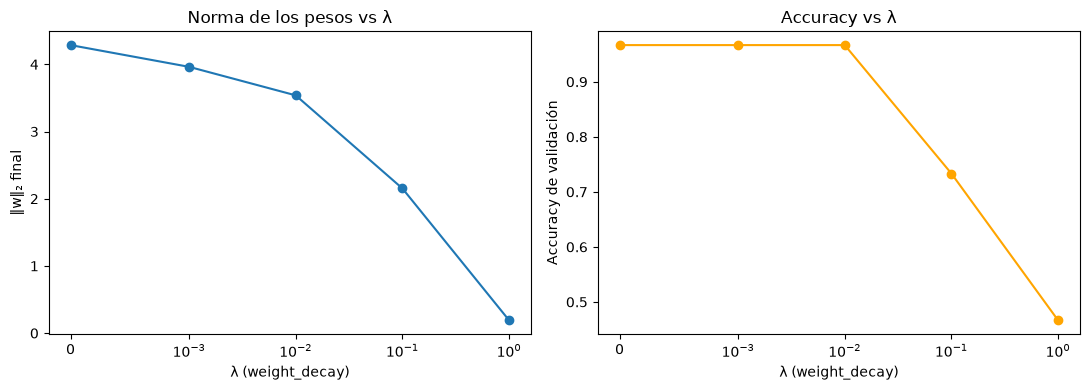

In [8]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

def weight_norm(model):
    """Norma L2 total de todos los pesos del modelo (concatenando todos los parámetros)."""
    return torch.cat([p.detach().flatten() for p in model.parameters()]).norm(2).item()

lambdas_l2 = [0, 1e-3, 1e-2, 1e-1, 1]
norms_l2 = []
accs_l2 = []

for lam in lambdas_l2:
    torch.manual_seed(0)  # mismo punto de partida para cada corrida
    model = IrisMLP()
    opt = torch.optim.Adam(model.parameters(), lr=1e-2, weight_decay=lam)
    trainer = Trainer(model, iris_train, iris_val, opt, l1=0.0)
    hist = trainer.fit(max_epochs=20, verbose=False)

    norms_l2.append(weight_norm(model))
    accs_l2.append(hist["val_acc"][-1])
    print(f"λ={lam:<8} norma_pesos={norms_l2[-1]:.3f}  val_acc={accs_l2[-1]:.3f}")

# --- gráficos ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(lambdas_l2, norms_l2, marker="o")
axes[0].set_xscale("symlog", linthresh=1e-3)  # symlog porque lambda=0 no admite log puro
axes[0].set_xlabel("λ (weight_decay)")
axes[0].set_ylabel("‖w‖₂ final")
axes[0].set_title("Norma de los pesos vs λ")

axes[1].plot(lambdas_l2, accs_l2, marker="o", color="orange")
axes[1].set_xscale("symlog", linthresh=1e-3)
axes[1].set_xlabel("λ (weight_decay)")
axes[1].set_ylabel("Accuracy de validación")
axes[1].set_title("Accuracy vs λ")

plt.tight_layout()
plt.show()

Los pesos decrecen
Decrece el desempeño en validacion pero porque es un dataset muy bobo intuyo

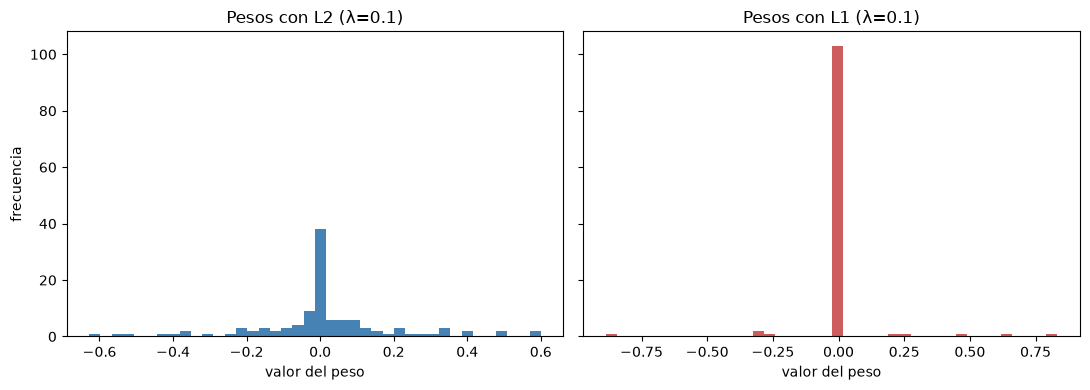

L2: 15.2% de pesos ~0
L1: 48.2% de pesos ~0


In [9]:
def get_all_weights(model):
    """Concatena todos los pesos (sin bias, para ver mejor la dispersión) en un solo array."""
    return torch.cat([p.detach().flatten() for name, p in model.named_parameters()
                       if "weight" in name]).numpy()

lam_grande = 1e-1  # mismo lambda "grande" para comparar L1 vs L2 en igualdad de condiciones

# --- entrenar con L2 grande ---
torch.manual_seed(0)
model_l2 = IrisMLP()
opt_l2 = torch.optim.Adam(model_l2.parameters(), lr=1e-2, weight_decay=lam_grande)
Trainer(model_l2, iris_train, iris_val, opt_l2, l1=0.0).fit(max_epochs=20)

# --- entrenar con L1 grande (weight_decay=0, l1=lam_grande) ---
torch.manual_seed(0)
model_l1 = IrisMLP()
opt_l1 = torch.optim.Adam(model_l1.parameters(), lr=1e-2, weight_decay=0.0)
Trainer(model_l1, iris_train, iris_val, opt_l1, l1=lam_grande).fit(max_epochs=20)

w_l2 = get_all_weights(model_l2)
w_l1 = get_all_weights(model_l1)

# --- histogramas ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

axes[0].hist(w_l2, bins=40, color="steelblue")
axes[0].set_title(f"Pesos con L2 (λ={lam_grande})")
axes[0].set_xlabel("valor del peso")
axes[0].set_ylabel("frecuencia")

axes[1].hist(w_l1, bins=40, color="indianred")
axes[1].set_title(f"Pesos con L1 (λ={lam_grande})")
axes[1].set_xlabel("valor del peso")

plt.tight_layout()
plt.show()

# --- cuantificar la dispersión (sparsity) ---
umbral = 1e-3
print(f"L2: {(abs(w_l2) < umbral).mean()*100:.1f}% de pesos ~0")
print(f"L1: {(abs(w_l1) < umbral).mean()*100:.1f}% de pesos ~0")

---
### Ejercicio 2: normalización por lotes y dropout

a) La _batch norm_ estima media y desvío de las activaciones **en cada lote**. Pero en evaluación podemos recibir de a un solo dato: ¿de dónde salen entonces esos valores?

b) Modificar `IrisMLP` para aceptar `use_batch_norm` en el constructor (ayuda: `nn.BatchNorm1d`).

c) Definir una `NetCNN` con normalización por lotes después de cada convolución (ayuda: `nn.BatchNorm2d` — ¿en qué difiere de la 1d?).

d) Agregar `dropout` con probabilidad configurable en ambas redes (con `p=0` se recupera el comportamiento original).

e) Entrenar `NetCNN` en MNIST con y sin BN+dropout y comparar. Recordar `model.train()` / `model.eval()`: ¿qué efecto tiene cada uno? ¿Qué diferencia hay con `torch.no_grad()`?

In [18]:
import copy
class irisMLP_PRO(nn.Module):
    def __init__(self, n_in= 4, n_hidden =16, n_out = 3, lr = 0.01 ,use_batch_norm = False):
        super().__init__()

        #flujo y activaciones
        #self.relu = nn.ReLU()

        if use_batch_norm ==True:
            self.bn = nn.BatchNorm1d(n_hidden)
        else:
            self.bn = nn.Identity()

        self.block_iris = nn.Sequential(
            nn.Linear(n_in, n_hidden),
            self.bn,
            nn.ReLU(),
            nn.Linear(n_hidden, n_out)
        )

        #config
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.to(self.device)

        #optimizacion
        self.loss_func = nn.CrossEntropyLoss(reduction = "mean")
        self.optim = torch.optim.Adam(self.parameters(), lr = lr)
        

    def forward(self, x):
        return self.block_iris(x)

    def fit(self, train_loader):
        self.train()
        total =0
        n = 0
        for X, y in train_loader:
            X, y = X.to(self.device), y.to(self.device)
            self.optim.zero_grad()
            out = self.forward(X)
            loss_func = self.loss_func(out, y)
            loss_func.backward()

            total += loss_func.item() *len(X)
            n += len(X)
            
            self.optim.step() #actualizamos los gradientes
        return total/n #el promedio de errores por epocas

    @torch.no_grad()
    def test(self, valid_loader):

        self.eval()
        total = 0
        n = 0
        for X, y in valid_loader:
            X = X.to(self.device)
            y = y.to(self.device)

            out = self.forward(X)
            loss_func = self.loss_func(out, y)

            total += loss_func.item() * len(X)
            n += len(X)
    
        return  total/n

    @torch.no_grad()
    def predict(self, X):
        self.eval()
        X = X.to(self.device)
        return self.forward(X)


    @torch.no_grad()
    def test_accuracy(self, loader):
        self.eval()
        correct = 0
        n = 0
        for X, y in loader:
            X, y = X.to(self.device), y.to(self.device)

            out = self.forward(X)
            pred = out.argmax(dim=1)   # clase con mayor logit
            correct += (pred == y).sum().item()
            n += len(X)

        return correct / n

    


def entrenar(model, train_loader, valid_loader, patience=20, epochs=500, verbose=True, noise_std=0.0):
    log = {"train": [], "valid": []}
    mejor_loss = float("inf")
    mejor_pesos = None
    epocas_sin_mejora = 0

    for ep in range(epochs):
        train_loss = model.fit(train_loader, noise_std=noise_std)   # ← se agrega acá
        valid_loss = model.test(valid_loader)

        log["train"].append(train_loss)
        log["valid"].append(valid_loss)

        if valid_loss < mejor_loss:
            mejor_loss = valid_loss
            mejor_pesos = copy.deepcopy(model.state_dict())
            epocas_sin_mejora = 0
        else:
            epocas_sin_mejora += 1

        if epocas_sin_mejora >= patience:
            if verbose:
                print(f"Early stopping en época {ep}, mejor valid loss: {mejor_loss:.4f}")
            break

    if mejor_pesos is not None:
        model.load_state_dict(mejor_pesos)
    return log


In [11]:
modelo = irisMLP_PRO(lr = 1e-3, use_batch_norm=True)
modelo2 = irisMLP_PRO(lr = 1e-3, use_batch_norm=False)


log = entrenar(modelo, iris_train, iris_val)
log2 = entrenar(modelo2, iris_train, iris_val)
acc1 = modelo.test_accuracy(iris_val)
acc2 = modelo2.test_accuracy(iris_val)
print(f"Accuracy en test: {acc1:.3f}")
print(f"Accuracy en test2: {acc2:.3f}")

Early stopping en época 78, mejor valid loss: 0.4104
Accuracy en test: 0.800
Accuracy en test2: 0.967


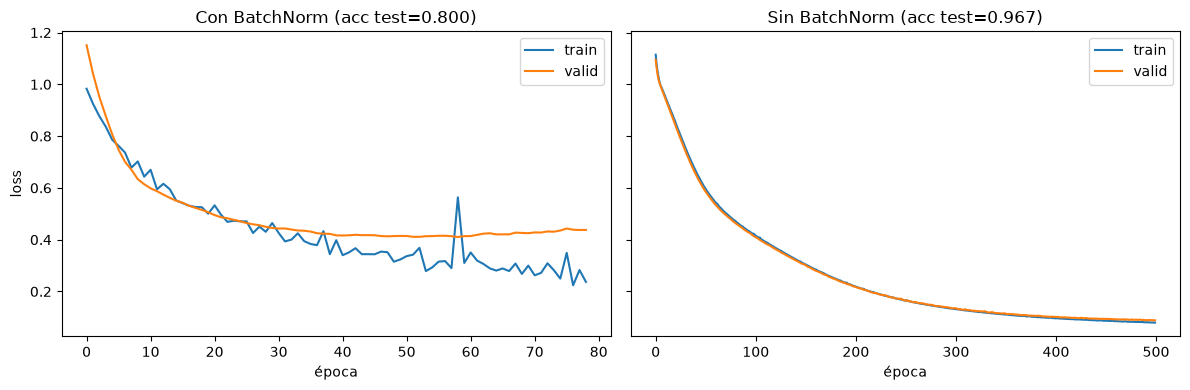

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

# --- Panel 1: modelo CON batch norm ---
axes[0].plot(log["train"], label="train")
axes[0].plot(log["valid"], label="valid")
axes[0].set_xlabel("época")
axes[0].set_ylabel("loss")
axes[0].set_title(f"Con BatchNorm (acc test={acc1:.3f})")
axes[0].legend()

# --- Panel 2: modelo SIN batch norm ---
axes[1].plot(log2["train"], label="train")
axes[1].plot(log2["valid"], label="valid")
axes[1].set_xlabel("época")
axes[1].set_title(f"Sin BatchNorm (acc test={acc2:.3f})")
axes[1].legend()

plt.tight_layout()
plt.show()

Comparacion de batch normalization vs normal

ahora probemos una CNN

In [17]:
import copy

class NetCNN(nn.Module):
    def __init__(self, n_out=10, use_batch_norm=False, p_drop=0.0, lr=1e-3):
        super().__init__()

        # --- bloque conv 1 ---
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=6, kernel_size=5)
        self.bn1 = nn.BatchNorm2d(6) if use_batch_norm else nn.Identity()
        self.pool1 = nn.MaxPool2d(kernel_size=2)

        # --- bloque conv 2 ---
        self.conv2 = nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5)
        self.bn2 = nn.BatchNorm2d(16) if use_batch_norm else nn.Identity()
        self.pool2 = nn.MaxPool2d(kernel_size=2)  # llega a (16,4,4)

        self.drop = nn.Dropout(p_drop)
        self.relu = nn.ReLU()

        n = 16 * 4 * 4

        # --- bloque fully-connected ---
        self.fc1 = nn.Linear(n, 120)
        self.bn3 = nn.BatchNorm1d(120) if use_batch_norm else nn.Identity()
        self.fc2 = nn.Linear(120, 84)
        self.bn4 = nn.BatchNorm1d(84) if use_batch_norm else nn.Identity()
        self.fc3 = nn.Linear(84, n_out)

        # --- config ---
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.to(self.device)

        # --- optimización ---
        self.loss_func = nn.CrossEntropyLoss(reduction="mean")
        self.optim = torch.optim.Adam(self.parameters(), lr=lr)

    def forward(self, x):
        x = self.conv1(x)     # (6,24,24)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.pool1(x)     # (6,12,12)

        x = self.conv2(x)     # (16,8,8)
        x = self.bn2(x)
        x = self.relu(x)
        x = self.pool2(x)     # (16,4,4)

        x = x.flatten(start_dim=1)   # 256
        x = self.fc1(x)              # 120
        x = self.bn3(x)
        x = self.relu(x)
        x = self.drop(x)

        x = self.fc2(x)              # 84
        x = self.bn4(x)
        x = self.relu(x)
        x = self.drop(x)

        x = self.fc3(x)              # salida, sin dropout
        return x

    def fit(self, train_loader, noise_std=0.0):
        self.train()
        total, n = 0, 0
        for X, y in train_loader:
            X, y = X.to(self.device), y.to(self.device)

            if noise_std > 0:
                X = torch.clamp(X + noise_std * torch.randn_like(X), 0, 1)

            self.optim.zero_grad()
            out = self.forward(X)
            loss = self.loss_func(out, y)
            loss.backward()
            self.optim.step()

            total += loss.item() * len(X)
            n += len(X)
        return total / n

    @torch.no_grad()
    def test(self, loader):
        self.eval()
        total, n = 0, 0
        for X, y in loader:
            X, y = X.to(self.device), y.to(self.device)
            out = self.forward(X)
            loss = self.loss_func(out, y)
            total += loss.item() * len(X)
            n += len(X)
        return total / n

    @torch.no_grad()
    def predict(self, X):
        self.eval()
        X = X.to(self.device)
        return self.forward(X)

    @torch.no_grad()
    def test_accuracy(self, loader):
        self.eval()
        correct, n = 0, 0
        for X, y in loader:
            X, y = X.to(self.device), y.to(self.device)
            out = self.forward(X)
            pred = out.argmax(dim=1)
            correct += (pred == y).sum().item()
            n += len(X)
        return correct / n

época 1: train 1.2641 | val 0.4773 (acc 0.858)
época 2: train 0.3657 | val 0.3050 (acc 0.914)
época 3: train 0.2646 | val 0.2267 (acc 0.930)
época 4: train 0.2044 | val 0.1797 (acc 0.947)
época 5: train 0.1652 | val 0.1454 (acc 0.957)
época 6: train 0.1406 | val 0.1247 (acc 0.962)
época 7: train 0.1184 | val 0.1374 (acc 0.958)
época 8: train 0.1096 | val 0.1197 (acc 0.960)


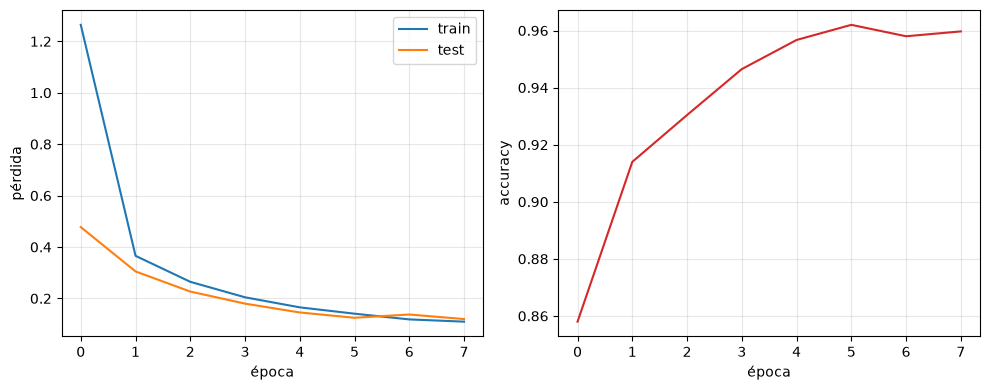

In [16]:
# probamos el modelo

torch.manual_seed(SEED)
modelo = NetCNN()
opt = optim.Adam(modelo.parameters(), lr=1e-3)

hist = Trainer(modelo, mnist_train_loader, mnist_test_loader,opt).fit(max_epochs =8, verbose = True)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(hist["train_loss"], label="train"); plt.plot(hist["val_loss"], label="test")
plt.xlabel("época"); plt.ylabel("pérdida"); plt.legend(); plt.grid(alpha=0.3)
plt.subplot(1, 2, 2)
plt.plot(hist["val_acc"], color="tab:red")
plt.xlabel("época"); plt.ylabel("accuracy"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Dropout

In [ ]:
# probamos hacer el dropout
import time
configs = [
    ("base", dict(use_batch_norm = False, p_drop=0)),
    ("solo BN", dict(use_batch_norm = True, p_drop = 0)),
    ("solo dropout", dict(use_batch_norm = False, p_drop=0.3)),
    ("both", dict(use_batch_norm = True, p_drop =0.3))
]
epoch =10
resultados ={}

for nombre, kwargs in configs:
    torch.manual_seed(SEED)
    modelo = NetCNN(**kwargs)
    opt = optim.Adam(modelo.parameters(), lr = 1e-3)
    t0 = time.time()
    hist = Trainer(modelo, mnist_train_loader, mnist_test_loader, opt).fit(epoch)
    seg = time.time() -t0
    _, acc = evaluar(modelo, mnist_test_loader)

    resultados[nombre] = hist
    print(f"{nombre:<13} | acc final {acc:.4f} | "
          f"train loss {hist['train_loss'][-1]:.4f} | {seg:.0f} s")


# ---------- curvas ----------
paneles = [("train_loss", "pérdida de entrenamiento"),
           ("val_loss",   "pérdida de validación"),
           ("val_acc",    "accuracy de validación")]

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, (clave, titulo) in zip(axs, paneles):
    for nombre, hist in resultados.items():
        ax.plot(hist[clave], marker="o", ms=3, label=nombre)
    ax.set_xlabel("época"); ax.set_title(titulo); ax.grid(alpha=0.3)
axs[0].legend()
plt.tight_layout(); plt.show()

# ---------- brecha train-val: ¿cuánto sobreajusta cada una? ----------
plt.figure(figsize=(6, 4))
for nombre, hist in resultados.items():
    brecha = np.array(hist["val_loss"]) - np.array(hist["train_loss"])
    plt.plot(brecha, marker="o", ms=3, label=nombre)
plt.axhline(0, color="gray", lw=0.8)
plt.xlabel("época"); plt.ylabel("val_loss − train_loss")
plt.title("brecha de generalización"); plt.legend(); plt.grid(alpha=0.3)
plt.show()



---
### Ejercicio 3: optimizadores

Probar distintos optimizadores disponibles, sobre MNIST con `NetCNN`:
```python
optim.SGD(model.parameters(), lr=0.01)
optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
optim.Adagrad(model.parameters(), lr=0.01)
optim.Adam(model.parameters(), lr=0.001)
optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.01)
```
Lanzar $N=5$ entrenamientos con cada optimizador (semillas distintas), promediar las curvas de pérdida de entrenamiento y comparar velocidad de convergencia y desempeño final. Si demora demasiado probar primero con $N=2$, y lanzar luego las $5$.

**Nota**: `Adam(weight_decay=λ)` y `AdamW(weight_decay=λ)` no hacen exactamente lo mismo (L2 dentro del gradiente adaptado vs. _decoupled weight decay_).

In [ ]:
### Se provee la estructura macro del código. Completar el core del ajuste
from torch import optim

def hacer_opt(nombre, params):
    return {
        "SGD":          lambda: optim.SGD(params, lr=0.01),
        "SGD+momentum": lambda: optim.SGD(params, lr=0.01, momentum=0.9),
        "Adagrad":      lambda: optim.Adagrad(params, lr=0.01),
        "Adam":         lambda: optim.Adam(params, lr=1e-3),
        "AdamW":        lambda: optim.AdamW(params, lr=1e-3, weight_decay=0.01),
    }[nombre]()

N = 5
resultados = {}
for nombre in ["SGD", "SGD+momentum", "Adagrad", "Adam", "AdamW"]:
    curvas, accs = [], []
    for semilla in range(N):
        torch.manual_seed(semilla)
        # Completar...

        curvas.append(h["train_loss"]); accs.append(h["val_acc"][-1])
    resultados[nombre] = (np.mean(curvas, axis=0), np.mean(accs))

plt.figure(figsize=(8, 4.5))
for nombre, (curva, acc) in resultados.items():
    plt.plot(curva, marker="o", label=f"{nombre} (acc test {acc:.3f})")
plt.xlabel("época"); plt.ylabel("pérdida de entrenamiento (promedio de 2 corridas)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

---
### Ejercicio 4: early stopping

Si el modelo entrena **de más**, empieza a memorizar el conjunto de entrenamiento y su desempeño en datos nuevos empeora. El _early stopping_ monitorea la pérdida de **validación** y corta cuando deja de mejorar, quedándose con los **mejores pesos**.

Para que el sobreajuste sea evidente, entrenamos con **etiquetas ruidosas**: corrompemos al azar el **40%** de las etiquetas de un subconjunto de MNIST (2000 imágenes). La validación, en cambio, tiene sus etiquetas **correctas**. Una red que entrena demasiado terminará memorizando las etiquetas equivocadas.

a) Completar la función `entrenar` para que, con `early_stopping=True`, lleve la cuenta de la mejor pérdida de validación, guarde el `state_dict` correspondiente y **frene** si no mejora durante `patience` épocas, restaurando al final los mejores pesos (ayuda: `copy.deepcopy`).
b) Entrenar el mismo modelo **con** y **sin** early stopping; graficar las curvas de train y de validación, marcando la época de corte.
c) Comparar la **accuracy de test** de ambos. ¿Cuál generaliza mejor?

In [ ]:
### SOLUCIÓN
from copy import deepcopy
from torch.utils.data import TensorDataset

# --- train con ETIQUETAS RUIDOSAS (40% cambiadas al azar) ---
N_TR, FRAC = 2000, 0.4
Xtr = torch.stack([mnist_train_full[i][0] for i in range(N_TR)])
ytr = torch.tensor([mnist_train_full[i][1] for i in range(N_TR)])
gen = torch.Generator().manual_seed(0)
n_corrupt = int(FRAC * N_TR)
idx = torch.randperm(N_TR, generator=gen)[:n_corrupt]
ytr_ruido = ytr.clone()
ytr_ruido[idx] = torch.randint(0, 10, (n_corrupt,), generator=gen)
train_es = DataLoader(TensorDataset(Xtr, ytr_ruido), batch_size=64, shuffle=True)

# validación LIMPIA (etiquetas correctas, imágenes no vistas)
Xval = torch.stack([mnist_train_full[i][0] for i in range(9000, 10000)])
yval = torch.tensor([mnist_train_full[i][1] for i in range(9000, 10000)])
val_es = DataLoader(TensorDataset(Xval, yval), batch_size=256)


In [ ]:

# a) Completar la función entrenar

def entrenar(model, train_loader, val_loader, max_epochs=60, lr=1e-3, early_stopping=False, patience=8):
    #lo primero siempre es seleccionar el device

    #configu inicial
    model = model.to(device)
    opt = optim.Adam(model.parameters(), lr= lr)
    criterio = nn.CrossEntropyLoss(reduction = 'sum')
    hist = {"train": [], "val": []}

    #validacion
    mejor_val = float("inf")
    mejor_ep = 0
    mejores_pesos = deepcopy(model.state_dict())
    sin_mejora = 0


    for ep in range(max_epochs):
        model.train()
        total_loss =0
        n = 0

        #recorro los batches
        for X,y in train_loader:
            X,y = X.to(device), y.to(device) 
            opt.zero_grad() #
            loss = criterio(model(X), y) #es el acumulado
            loss.backward()
            opt.step()

            total_loss += loss.item()
            n += len(X)
        loss_epoch = total_loss/n
        val_err, _ = evaluar(model, val_loader)

        hist["train"].append(loss_epoch)
        hist["val"].append(val_err)

        if val_err<mejor_val:
            mejor_val, mejor_ep = val_err, ep
            mejores_pesos = deepcopy(model.state_dict())
            sin_mejora =0
        else:
            sin_mejora +=1
            if early_stopping and sin_mejora>=patience:
                print(f"corte en la época {ep} | mejor época: {mejor_ep} "
                      f"(val loss {mejor_val:.4f})")
                break

    return model, hist, mejor_ep








In [ ]:
# b) con y sin early stopping (misma semilla e inicialización)
torch.manual_seed(SEED)
modelo_es, _, mejor_ep = entrenar(NetCNN(), train_es, val_es, early_stopping=True)
torch.manual_seed(SEED)
modelo_full, hist_full, _ = entrenar(NetCNN(), train_es, val_es, early_stopping=False)

plt.figure(figsize=(7, 4))
plt.plot(hist_full["train"], label="train (etiquetas ruidosas)")
plt.plot(hist_full["val"], label="validación (limpia)")
plt.axvline(mejor_ep, color="gray", ls="--", label=f"early stopping (época {mejor_ep})")
plt.xlabel("época"); plt.ylabel("pérdida"); plt.legend(); plt.grid(alpha=0.3)
plt.title("la validación limpia se da vuelta: la red memoriza las etiquetas ruidosas")
plt.show()

# c) test (con etiquetas correctas)
_, acc_es = evaluar(modelo_es, mnist_test_loader)
_, acc_full = evaluar(modelo_full, mnist_test_loader)
print(f"test accuracy con early stopping:        {acc_es:.3f}")
print(f"test accuracy entrenando hasta el final: {acc_full:.3f}")

In [ ]:
# ---------- prueba rápida: ¿funciona el mecanismo? ----------
torch.manual_seed(SEED)
m, h, ep = entrenar(NetCNN(), train_es, val_es, max_epochs=6, early_stopping=False)
print("devuelve:", type(m).__name__, "| épocas:", len(h["train"]), "| mejor época:", ep)
print("train:", [f"{v:.3f}" for v in h["train"]])
print("val:  ", [f"{v:.3f}" for v in h["val"]])


devuelve: NetCNN | épocas: 6 | mejor época: 4
train: ['2.269', '1.994', '1.820', '1.718', '1.672', '1.622']
val:   ['2.054', '1.389', '1.093', '1.019', '0.812', '0.870']


In [ ]:
# ---------- prueba: ¿el early stopping realmente restaura los mejores pesos? ----------
torch.manual_seed(SEED)
m_es, h_es, ep_es = entrenar(NetCNN(), train_es, val_es, max_epochs=60,
                             early_stopping=True, patience=8)

vl_restaurado, acc_restaurado = evaluar(m_es, val_es)
print(f"épocas corridas:      {len(h_es['train'])}")
print(f"mejor época:          {ep_es}")
print(f"val loss en el hist:  {h_es['val'][ep_es]:.4f}")
print(f"val loss del modelo:  {vl_restaurado:.4f}   <- deben coincidir")
print(f"val loss última época:{h_es['val'][-1]:.4f}   <- debe ser peor")


corte en la época 25 | mejor época: 17 (val loss 0.6318)
épocas corridas:      26
mejor época:          17
val loss en el hist:  0.6318
val loss del modelo:  0.7489   <- deben coincidir
val loss última época:0.7489   <- debe ser peor


corte en la época 25 | mejor época: 17 (val loss 0.6318)


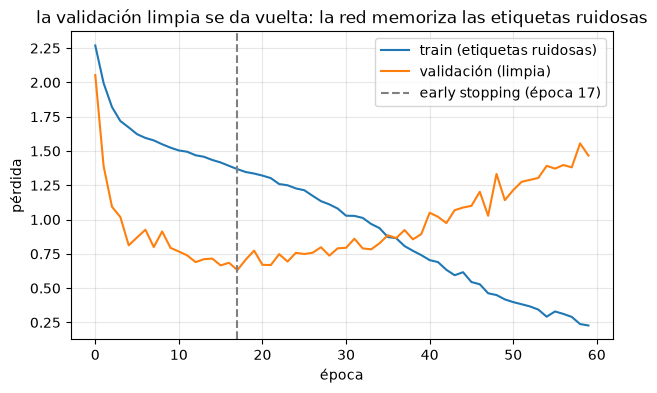

test accuracy con early stopping:        0.855
test accuracy entrenando hasta el final: 0.659


In [ ]:
# ---------- corrida completa: con vs sin (b y c del enunciado) ----------
torch.manual_seed(SEED)
modelo_es, _, mejor_ep = entrenar(NetCNN(), train_es, val_es, early_stopping=True)
torch.manual_seed(SEED)
modelo_full, hist_full, _ = entrenar(NetCNN(), train_es, val_es, early_stopping=False)

plt.figure(figsize=(7, 4))
plt.plot(hist_full["train"], label="train (etiquetas ruidosas)")
plt.plot(hist_full["val"], label="validación (limpia)")
plt.axvline(mejor_ep, color="gray", ls="--", label=f"early stopping (época {mejor_ep})")
plt.xlabel("época"); plt.ylabel("pérdida"); plt.legend(); plt.grid(alpha=0.3)
plt.title("la validación limpia se da vuelta: la red memoriza las etiquetas ruidosas")
plt.show()

_, acc_es = evaluar(modelo_es, mnist_test_loader)
_, acc_full = evaluar(modelo_full, mnist_test_loader)
print(f"test accuracy con early stopping:        {acc_es:.3f}")
print(f"test accuracy entrenando hasta el final: {acc_full:.3f}")


---
### Ejercicio 5: aumentación de datos con ruido

**Aumentar los datos** = generar variantes de cada ejemplo para que el modelo vea 'más datos'. La variante más simple: **agregar ruido** a las entradas durante el entrenamiento (inyección de ruido, una forma de regularización). Lo que gana el modelo es **robustez**: aprende a clasificar aun cuando la entrada está degradada.

Entrenamos la `NetCNN` sobre un subconjunto chico de MNIST (500 imágenes) y la evaluamos sobre un test **limpio** y sobre tests cada vez más **ruidosos**.

a) Visualizar un lote con ruido gaussiano agregado (`x + σ·randn`, recortado a $[0,1]$).
b) Completar el bucle para que, si `noise_std > 0`, agregue ruido gaussiano **distinto en cada época** a las entradas (data augmentation).
c) Entrenar **sin** aumentación (`noise_std=0`) y **con** aumentación (`noise_std=0.5`), y comparar la accuracy sobre test limpio y ruidoso. ¿Qué gana la aumentación, y a qué costo?

In [ ]:
class NoisyDataset(Dataset):
    def __init__(self, X,y , noise_std=0.5):
        aux= torch.tensor(X, dtype = torch.float32)
        self.X =torch.clamp(aux + noise_std * torch.randn_like(aux), 0, 1)
        self.y = torch.tensor(y, dtype=torch.long)
    def __len__(self):
        return len(self.base)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

#me piden ruido distinto a cada epoca xd

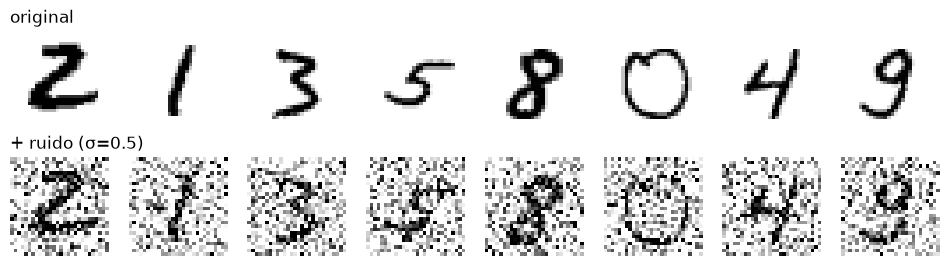

In [ ]:
# a) Lote con ruido gaussiano. Subconjunto chico y visualización del ruido

peq_train = DataLoader(torch.utils.data.Subset(mnist_train_full, range(500)),
                       batch_size=64, shuffle=True)

x_lote, _ = next(iter(peq_train))
x_ruido = torch.clamp(x_lote + 0.5 * torch.randn_like(x_lote), 0, 1)
fig, axs = plt.subplots(2, 8, figsize=(12, 3))
for k in range(8):
    axs[0, k].imshow(x_lote[k].squeeze(), cmap="gray_r"); axs[0, k].axis("off")
    axs[1, k].imshow(x_ruido[k].squeeze(), cmap="gray_r"); axs[1, k].axis("off")
axs[0, 0].set_title("original", loc="left"); axs[1, 0].set_title("+ ruido (σ=0.5)", loc="left")
plt.show()

In [19]:
modelo_sin_aug = NetCNN()
log_sin = entrenar(modelo_sin_aug, mnist_train_loader, mnist_test_loader, noise_std=0.0)

modelo_con_aug = NetCNN()
log_con = entrenar(modelo_con_aug, mnist_train_loader, mnist_test_loader, noise_std=0.5)

Early stopping en época 38, mejor valid loss: 0.0726
Early stopping en época 86, mejor valid loss: 0.0585


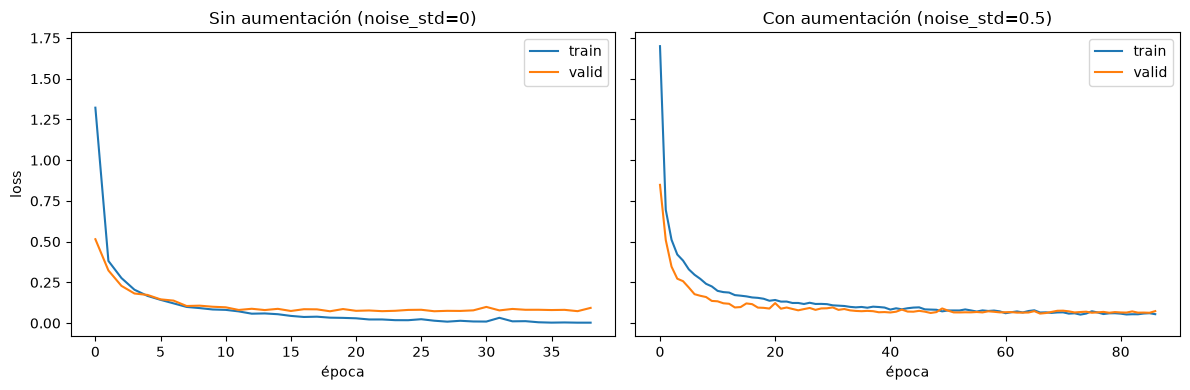

In [20]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

# --- Panel 1: sin aumentación ---
axes[0].plot(log_sin["train"], label="train")
axes[0].plot(log_sin["valid"], label="valid")
axes[0].set_xlabel("época")
axes[0].set_ylabel("loss")
axes[0].set_title("Sin aumentación (noise_std=0)")
axes[0].legend()

# --- Panel 2: con aumentación ---
axes[1].plot(log_con["train"], label="train")
axes[1].plot(log_con["valid"], label="valid")
axes[1].set_xlabel("época")
axes[1].set_title("Con aumentación (noise_std=0.5)")
axes[1].legend()

plt.tight_layout()
plt.show()

In [21]:
print(modelo_sin_aug.test_accuracy(mnist_test_loader))
print(modelo_con_aug.test_accuracy(mnist_test_loader))

0.9758
0.9846
